## 2012 NBA Finals Analysis: How the leBron James and the Miami Heat dominated

### This notebook is covers gathering the data for the analysis using pandas and numpy.

## Libaries used
### Pandas: Gathering matchup data and numbers from boxscores during the finals series to create hypotheses

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nba_api.stats.endpoints import leaguegamefinder

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)
print("All libraries loaded successfully!")

pandas: 3.0.3
numpy: 1.26.4
matplotlib: 3.7.0
seaborn: 0.13.2
All libraries loaded successfully!


In [49]:
from nba_api.stats.endpoints import leaguegamefinder
from nba_api.stats.static import teams
import time

nba_teams = teams.get_teams()
heat = [team for team in nba_teams if team['abbreviation'] == 'MIA'][0]
thunder = [team for team in nba_teams if team['abbreviation'] == 'OKC'][0]

print("Heat team info:", heat)
print("Thunder team info:", thunder)



Heat team info: {'id': 1610612748, 'full_name': 'Miami Heat', 'abbreviation': 'MIA', 'nickname': 'Heat', 'city': 'Miami', 'state': 'Florida', 'year_founded': 1988}
Thunder team info: {'id': 1610612760, 'full_name': 'Oklahoma City Thunder', 'abbreviation': 'OKC', 'nickname': 'Thunder', 'city': 'Oklahoma City', 'state': 'Oklahoma', 'year_founded': 1967}


In [50]:
gamefinder = leaguegamefinder.LeagueGameFinder(team_id_nullable=heat['id'], season_nullable='2011-12', season_type_nullable='Playoffs')

heat_playoffs = gamefinder.get_data_frames()[0]

print("Shape", heat_playoffs.shape)
print("\nColumns:", heat_playoffs.columns)
print("\nAll Heat playoff games:")
heat_playoffs

Shape (23, 28)

Columns: Index(['SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID',
       'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'PTS', 'FGM', 'FGA', 'FG_PCT',
       'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB',
       'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PLUS_MINUS'],
      dtype='str')

All Heat playoff games:


,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,PTS,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PLUS_MINUS
0,42011,1610612748,MIA,Miami Heat,0041100405,2012-06-21,MIA vs. OKC,W,241,121,...,0.818,8,33,41,25,8,7,13,21,15.0
1,42011,1610612748,MIA,Miami Heat,0041100404,2012-06-19,MIA vs. OKC,W,239,104,...,0.720,9,31,40,19,8,2,9,18,6.0
2,42011,1610612748,MIA,Miami Heat,0041100403,2012-06-17,MIA vs. OKC,W,240,91,...,0.886,14,31,45,13,6,5,12,19,6.0
3,42011,1610612748,MIA,Miami Heat,0041100402,2012-06-14,MIA @ OKC,W,238,100,...,0.880,11,29,40,13,5,4,13,21,4.0
4,42011,1610612748,MIA,Miami Heat,0041100401,2012-06-12,MIA @ OKC,L,240,94,...,0.778,7,28,35,20,6,1,10,19,-11.0
5,42011,1610612748,MIA,Miami Heat,0041100307,2012-06-09,MIA vs. BOS,W,240,101,...,0.741,9,29,38,16,8,3,13,14,13.0
6,42011,1610612748,MIA,Miami Heat,0041100306,2012-06-07,MIA @ BOS,W,241,98,...,0.773,10,34,44,15,8,4,12,21,19.0
7,42011,1610612748,MIA,Miami Heat,0041100305,2012-06-05,MIA vs. BOS,L,239,90,...,0.760,12,37,49,13,6,3,15,21,-4.0
8,42011,1610612748,MIA,Miami Heat,0041100304,2012-06-03,MIA @ BOS,L,265,91,...,0.708,7,33,40,20,6,6,17,28,-2.0
9,42011,1610612748,MIA,Miami Heat,0041100303,2012-06-01,MIA @ BOS,L,241,91,...,0.500,6,26,32,20,5,5,10,24,-10.0


In [51]:
heat_playoffs.head()

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,PTS,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PLUS_MINUS
0,42011,1610612748,MIA,Miami Heat,0041100405,2012-06-21,MIA vs. OKC,W,241,121,...,0.818,8,33,41,25,8,7,13,21,15.0
1,42011,1610612748,MIA,Miami Heat,0041100404,2012-06-19,MIA vs. OKC,W,239,104,...,0.720,9,31,40,19,8,2,9,18,6.0
2,42011,1610612748,MIA,Miami Heat,0041100403,2012-06-17,MIA vs. OKC,W,240,91,...,0.886,14,31,45,13,6,5,12,19,6.0
3,42011,1610612748,MIA,Miami Heat,0041100402,2012-06-14,MIA @ OKC,W,238,100,...,0.880,11,29,40,13,5,4,13,21,4.0
4,42011,1610612748,MIA,Miami Heat,0041100401,2012-06-12,MIA @ OKC,L,240,94,...,0.778,7,28,35,20,6,1,10,19,-11.0


In [52]:
finals_games = heat_playoffs[heat_playoffs['GAME_ID'].str.contains('0411004')]
finals_games[['GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL']]

,GAME_ID,GAME_DATE,MATCHUP,WL
0,0041100405,2012-06-21,MIA vs. OKC,W
1,0041100404,2012-06-19,MIA vs. OKC,W
2,0041100403,2012-06-17,MIA vs. OKC,W
3,0041100402,2012-06-14,MIA @ OKC,W
4,0041100401,2012-06-12,MIA @ OKC,L


In [53]:
from nba_api.stats.endpoints import boxscoretraditionalv3
import time

# Good practice to pause between API calls to avoid hitting rate limits
time.sleep(1)

game1_id = finals_games[finals_games['GAME_ID'].str.endswith('401')]['GAME_ID'].values[0]
boxscore_game1 = boxscoretraditionalv3.BoxScoreTraditionalV3(game_id=game1_id)
boxscore_game1.get_data_frames()

[        gameId      teamId       teamCity teamName teamTricode teamSlug  \
 0   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 1   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 2   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 3   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 4   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 5   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 6   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 7   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 8   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 9   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 10  0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 11  0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 12  0041100

In [54]:
game_level_boxscores = []
for game_id in finals_games['GAME_ID']:
    print("Fetching box score for game ID:", game_id)
    boxscore = boxscoretraditionalv3.BoxScoreTraditionalV3(game_id=game_id)
    game_level_boxscore = boxscore.get_data_frames()[0]
    game_level_boxscore['GAME_NUMBER'] = int(game_id[-1])
    game_level_boxscores.append(game_level_boxscore)
    time.sleep(1)

Fetching box score for game ID: 0041100405
Fetching box score for game ID: 0041100404
Fetching box score for game ID: 0041100403
Fetching box score for game ID: 0041100402
Fetching box score for game ID: 0041100401


In [55]:
all_games_df = pd.concat(game_level_boxscores, ignore_index=True).sort_values(by=['GAME_NUMBER', 'teamTricode'], ascending=[True, True])
print(all_games_df)

         gameId      teamId       teamCity teamName teamTricode teamSlug  \
117  0041100401  1610612748          Miami     Heat         MIA     heat   
118  0041100401  1610612748          Miami     Heat         MIA     heat   
119  0041100401  1610612748          Miami     Heat         MIA     heat   
120  0041100401  1610612748          Miami     Heat         MIA     heat   
121  0041100401  1610612748          Miami     Heat         MIA     heat   
..          ...         ...            ...      ...         ...      ...   
21   0041100405  1610612760  Oklahoma City  Thunder         OKC  thunder   
22   0041100405  1610612760  Oklahoma City  Thunder         OKC  thunder   
23   0041100405  1610612760  Oklahoma City  Thunder         OKC  thunder   
24   0041100405  1610612760  Oklahoma City  Thunder         OKC  thunder   
25   0041100405  1610612760  Oklahoma City  Thunder         OKC  thunder   

     personId firstName familyName        nameI  ... reboundsDefensive  \
117      2544

In [56]:
print("Columns in the combined box score DataFrame:", all_games_df.columns)

Columns in the combined box score DataFrame: Index(['gameId', 'teamId', 'teamCity', 'teamName', 'teamTricode', 'teamSlug',
       'personId', 'firstName', 'familyName', 'nameI', 'playerSlug',
       'position', 'comment', 'jerseyNum', 'minutes', 'fieldGoalsMade',
       'fieldGoalsAttempted', 'fieldGoalsPercentage', 'threePointersMade',
       'threePointersAttempted', 'threePointersPercentage', 'freeThrowsMade',
       'freeThrowsAttempted', 'freeThrowsPercentage', 'reboundsOffensive',
       'reboundsDefensive', 'reboundsTotal', 'assists', 'steals', 'blocks',
       'turnovers', 'foulsPersonal', 'points', 'plusMinusPoints',
       'GAME_NUMBER'],
      dtype='str')


In [57]:
key_players_df = all_games_df[all_games_df['nameI'].isin(['L. James', 'K. Durant', 'J. Harden'])]
key_players_df[['firstName', 'familyName', 'GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by=['GAME_NUMBER', 'familyName'], ascending=[True, True])

,firstName,familyName,GAME_NUMBER,points,reboundsTotal,assists,turnovers,plusMinusPoints
104,Kevin,Durant,1,36,8,4,2,15.0
110,James,Harden,1,5,0,3,1,2.0
117,LeBron,James,1,30,9,4,4,-11.0
78,Kevin,Durant,2,32,3,1,2,-9.0
83,James,Harden,2,21,4,2,2,13.0
91,LeBron,James,2,32,8,5,2,6.0
65,Kevin,Durant,3,25,6,0,5,-3.0
70,James,Harden,3,9,6,6,2,-5.0
52,LeBron,James,3,29,14,3,4,8.0
39,Kevin,Durant,4,28,2,3,3,0.0


In [58]:
lebron_df = key_players_df[key_players_df['nameI'] == 'L. James']
lebron_df = lebron_df[['GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by='GAME_NUMBER')
print(lebron_df)

     GAME_NUMBER  points  reboundsTotal  assists  turnovers  plusMinusPoints
117            1      30              9        4          4            -11.0
91             2      32              8        5          2              6.0
52             3      29             14        3          4              8.0
26             4      26              9       12          3              8.0
0              5      26             11       13          6             20.0


In [59]:
durant_df = key_players_df[key_players_df['nameI'] == 'K. Durant']
durant_df = durant_df[['GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by='GAME_NUMBER') 
print(durant_df)

     GAME_NUMBER  points  reboundsTotal  assists  turnovers  plusMinusPoints
104            1      36              8        4          2             15.0
78             2      32              3        1          2             -9.0
65             3      25              6        0          5             -3.0
39             4      28              2        3          3              0.0
13             5      32             11        3          7            -23.0


In [60]:
print(durant_df['points'].mean())
print(durant_df['turnovers'].mean())


30.6
3.8


In [61]:
harden_df = key_players_df[key_players_df['nameI'] == 'J. Harden']
harden_df = harden_df[['GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by='GAME_NUMBER') 
print(harden_df)    

     GAME_NUMBER  points  reboundsTotal  assists  turnovers  plusMinusPoints
110            1       5              0        3          1              2.0
83             2      21              4        2          2             13.0
70             3       9              6        6          2             -5.0
45             4       8             10        2          4             -4.0
18             5      19              4        5          3            -17.0


In [62]:
print(harden_df['points'].mean())

12.4


# 3. Data Visualization
### The visualization below shows the points per game of LeBron James, Kevin Durant, and James Harden across the 2012 NBA Finals games. Each player's performance can be compared across the five games to identify trends and key moments in the series.

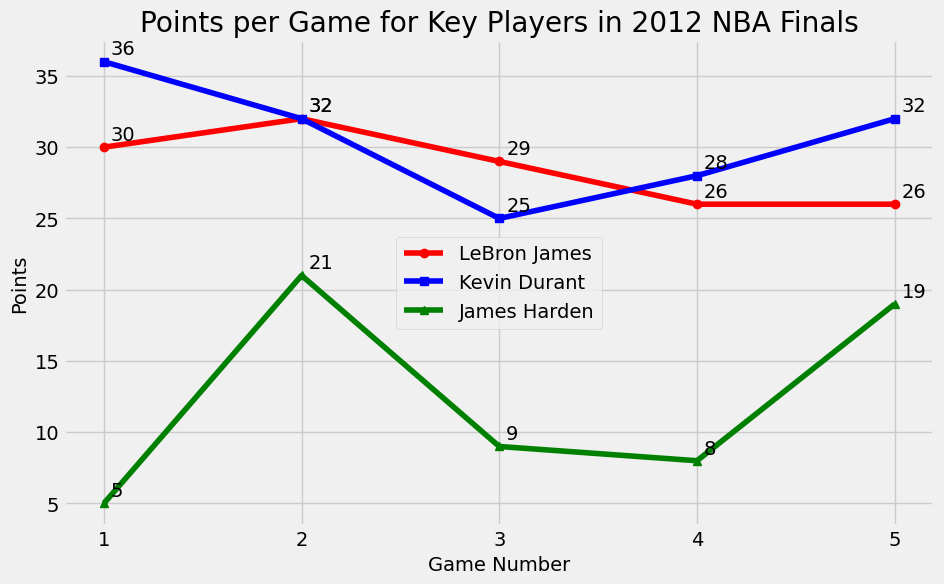

In [63]:
plt.style.use('fivethirtyeight')
# sns.set_style('darkgrid')
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title('Points per Game for Key Players in 2012 NBA Finals')
ax.set_xlabel('Game Number')
ax.set_ylabel('Points')
ax.set_xticks(lebron_df['GAME_NUMBER'])

lebron_plot = (lebron_df, 'LeBron James', 'red', 'o')
durant_plot = (durant_df, 'Kevin Durant', 'blue', 's')
harden_plot = (harden_df, 'James Harden', 'green', '^')

for frame, name, color, marker in [lebron_plot, durant_plot, harden_plot]:
    ax.plot(frame['GAME_NUMBER'], frame['points'], marker=marker, label=name, color=color)
    for _, row in frame.iterrows():
        ax.annotate(str(int(row['points'])), xy=(row['GAME_NUMBER'], row['points']), xytext=(5, 5), textcoords='offset points')

plt.legend()
plt.savefig('../data/points_per_game_key_players.png',)

plt.show()

In [64]:
all_games_df['eFGPercentage'] = (all_games_df['fieldGoalsMade'] + 0.5 * all_games_df['threePointersMade']) / all_games_df['fieldGoalsAttempted']
print(all_games_df[['nameI', 'GAME_NUMBER', 'fieldGoalsMade', 'threePointersMade', 'fieldGoalsAttempted', 'eFGPercentage']].sort_values(by='GAME_NUMBER', ascending=True))

           nameI  GAME_NUMBER  fieldGoalsMade  threePointersMade  \
117     L. James            1              11                  1   
116  N. Mohammed            1               0                  0   
115      R. Ivey            1               0                  0   
114   L. Hayward            1               0                  0   
113   C. Aldrich            1               0                  0   
..           ...          ...             ...                ...   
1     S. Battier            5               4                  3   
0       L. James            5               9                  0   
24       R. Ivey            5               2                  2   
11     T. Harris            5               0                  0   
25   N. Mohammed            5               0                  0   

     fieldGoalsAttempted  eFGPercentage  
117                   24       0.479167  
116                    0            NaN  
115                    0            NaN  
114            

In [65]:
all_games_df['minutes'].head(10)

117    45:50
118    41:45
119    28:37
120    42:29
121    35:27
122    33:39
123    10:07
124     2:06
125         
126         
Name: minutes, dtype: str

In [66]:
def convert_string_minutes_to_float(minutes_str):
    if isinstance(minutes_str, str) and ':' in minutes_str:
        minutes, seconds = minutes_str.split(':')
        return int(minutes) + int(seconds) / 60
    return 0.0

In [67]:
all_games_df['minutesPlayed'] = all_games_df['minutes'].apply(convert_string_minutes_to_float)
rotation_df = all_games_df[all_games_df['minutesPlayed'] >= 10]

In [68]:
all_games_df

,gameId,teamId,teamCity,teamName,teamTricode,teamSlug,personId,firstName,familyName,nameI,...,assists,steals,blocks,turnovers,foulsPersonal,points,plusMinusPoints,GAME_NUMBER,eFGPercentage,minutesPlayed
117,0041100401,1610612748,Miami,Heat,MIA,heat,2544,LeBron,James,L. James,...,4,4,0,4,1,30,-11.0,1,0.479167,45.833333
118,0041100401,1610612748,Miami,Heat,MIA,heat,2203,Shane,Battier,S. Battier,...,0,1,0,0,3,17,-6.0,1,0.888889,41.750000
119,0041100401,1610612748,Miami,Heat,MIA,heat,2617,Udonis,Haslem,U. Haslem,...,0,0,0,1,5,4,-10.0,1,0.333333,28.616667
120,0041100401,1610612748,Miami,Heat,MIA,heat,2548,Dwyane,Wade,D. Wade,...,8,1,0,3,3,19,-6.0,1,0.368421,42.483333
121,0041100401,1610612748,Miami,Heat,MIA,heat,201596,Mario,Chalmers,M. Chalmers,...,6,0,1,1,4,12,-3.0,1,0.857143,35.450000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,201161,Daequan,Cook,D. Cook,...,1,0,0,0,1,2,8.0,5,0.500000,4.733333
22,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,202332,Cole,Aldrich,C. Aldrich,...,0,0,0,0,0,2,8.0,5,1.000000,4.733333
23,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,202351,Lazar,Hayward,L. Hayward,...,0,0,0,0,1,2,8.0,5,0.500000,4.733333
24,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,2767,Royal,Ivey,R. Ivey,...,0,0,0,0,0,6,7.0,5,1.500000,3.016667


In [69]:
rotation_df

,gameId,teamId,teamCity,teamName,teamTricode,teamSlug,personId,firstName,familyName,nameI,...,assists,steals,blocks,turnovers,foulsPersonal,points,plusMinusPoints,GAME_NUMBER,eFGPercentage,minutesPlayed
117,0041100401,1610612748,Miami,Heat,MIA,heat,2544,LeBron,James,L. James,...,4,4,0,4,1,30,-11.0,1,0.479167,45.833333
118,0041100401,1610612748,Miami,Heat,MIA,heat,2203,Shane,Battier,S. Battier,...,0,1,0,0,3,17,-6.0,1,0.888889,41.750000
119,0041100401,1610612748,Miami,Heat,MIA,heat,2617,Udonis,Haslem,U. Haslem,...,0,0,0,1,5,4,-10.0,1,0.333333,28.616667
120,0041100401,1610612748,Miami,Heat,MIA,heat,2548,Dwyane,Wade,D. Wade,...,8,1,0,3,3,19,-6.0,1,0.368421,42.483333
121,0041100401,1610612748,Miami,Heat,MIA,heat,201596,Mario,Chalmers,M. Chalmers,...,6,0,1,1,4,12,-3.0,1,0.857143,35.450000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,2570,Kendrick,Perkins,K. Perkins,...,0,1,0,1,5,2,-14.0,5,0.250000,19.750000
17,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,201566,Russell,Westbrook,R. Westbrook,...,6,2,0,2,3,19,-23.0,5,0.200000,43.266667
18,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,201935,James,Harden,J. Harden,...,5,2,0,3,2,19,-17.0,5,0.590909,35.666667
19,0041100405,1610612760,Oklahoma City,Thunder,OKC,thunder,2555,Nick,Collison,N. Collison,...,1,0,0,0,3,2,3.0,5,0.333333,16.933333


In [70]:
team_efg = rotation_df.groupby(['teamTricode', 'GAME_NUMBER'])['eFGPercentage'].mean().reset_index()
print(team_efg)

  teamTricode  GAME_NUMBER  eFGPercentage
0         MIA            1       0.548006
1         MIA            2       0.503743
2         MIA            3       0.641234
3         MIA            4       0.553947
4         MIA            5       0.552413
5         OKC            1       0.604167
6         OKC            2       0.412388
7         OKC            3       0.435727
8         OKC            4       0.422768
9         OKC            5       0.442494


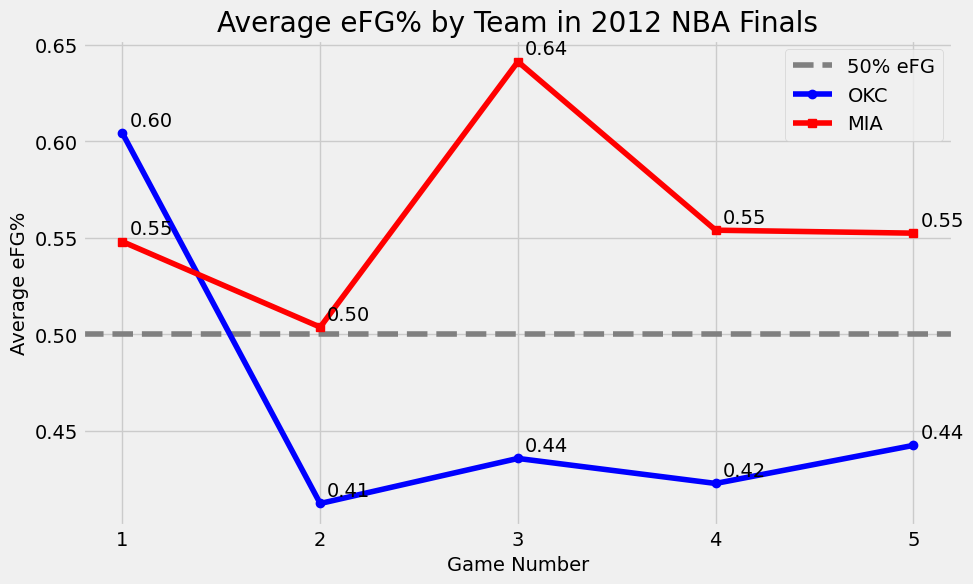

In [71]:
plt.style.use('fivethirtyeight')
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title('Average eFG% by Team in 2012 NBA Finals')
ax.set_xlabel('Game Number')
ax.set_ylabel('Average eFG%')
ax.set_xticks(team_efg['GAME_NUMBER'].unique())
okc_team_data = (team_efg[team_efg['teamTricode'] == 'OKC'], 'OKC', 'blue', 'o')
mia_team_data = (team_efg[team_efg['teamTricode'] == 'MIA'], 'MIA', 'red', 's')
ax.axhline(0.5, color='gray', linestyle='--', label='50% eFG')


for data, name, color, marker in [okc_team_data, mia_team_data]:
    ax.plot(data['GAME_NUMBER'], data['eFGPercentage'], marker=marker, label=name, color=color)
    for _, row in data.iterrows():
        ax.annotate(f"{row['eFGPercentage']:.2f}", xy=(row['GAME_NUMBER'], row['eFGPercentage']), xytext=(5, 5), textcoords='offset points')
    
ax.legend()
plt.savefig('../data/avg_efg.png')

#### This second graph compares both teams' eFG% over the 5 game span. Effective Field Goal Percentage (eFG%) accounts for 3 pointers made in its calculation. The big drop off after Game 1 from the Thunder gives us some more context on how the Heat won so handily. The dashed line represents the average eFG% of a team during the regular season and the Thunder never even came close in the final 4 games. Mean while, the Heat matched or topped it consistently, peaking in Game 3 when they dominated. 

In [72]:
four_factors_df = all_games_df.groupby(['teamTricode', 'GAME_NUMBER'])[['fieldGoalsMade', 'fieldGoalsAttempted', 'threePointersMade', 'freeThrowsMade', 'freeThrowsAttempted', 'reboundsOffensive', 'reboundsDefensive', 'turnovers']].sum().reset_index()
print(four_factors_df)

  teamTricode  GAME_NUMBER  fieldGoalsMade  fieldGoalsAttempted  \
0         MIA            1              36                   78   
1         MIA            2              36                   76   
2         MIA            3              28                   74   
3         MIA            4              38                   79   
4         MIA            5              40                   77   
5         OKC            1              40                   77   
6         OKC            2              34                   79   
7         OKC            3              33                   77   
8         OKC            4              40                   82   
9         OKC            5              36                   87   

   threePointersMade  freeThrowsMade  freeThrowsAttempted  reboundsOffensive  \
0                  8              14                   18                  7   
1                  6              22                   25                 11   
2                  4  

In [73]:
four_factors_merged = four_factors_df.merge(four_factors_df, on='GAME_NUMBER')
four_factors_merged = four_factors_merged[four_factors_merged['teamTricode_x'] != four_factors_merged['teamTricode_y']]
print(four_factors_merged[['teamTricode_x', 'teamTricode_y', 'GAME_NUMBER', 'reboundsOffensive_x', 'reboundsDefensive_y']])

   teamTricode_x teamTricode_y  GAME_NUMBER  reboundsOffensive_x  \
1            MIA           OKC            1                    7   
3            MIA           OKC            2                   11   
5            MIA           OKC            3                   14   
7            MIA           OKC            4                    9   
9            MIA           OKC            5                    8   
10           OKC           MIA            1                   10   
12           OKC           MIA            2                   10   
14           OKC           MIA            3                   11   
16           OKC           MIA            4                    8   
18           OKC           MIA            5                   10   

    reboundsDefensive_y  
1                    33  
3                    26  
5                    27  
7                    27  
9                    28  
10                   28  
12                   29  
14                   31  
16               

In [74]:
four_factors_merged['possessions'] = 0.96 * (four_factors_merged['fieldGoalsAttempted_x'] + four_factors_merged['turnovers_x'] + 0.44 * four_factors_merged['freeThrowsAttempted_x'] - four_factors_merged['reboundsOffensive_x'])
four_factors_merged['eFG%'] = (four_factors_merged['fieldGoalsMade_x'] + 0.5 * four_factors_merged['threePointersMade_x']) / four_factors_merged['fieldGoalsAttempted_x']
four_factors_merged['oREB%'] = four_factors_merged['reboundsOffensive_x'] / (four_factors_merged['reboundsOffensive_x'] + four_factors_merged['reboundsDefensive_y'])
four_factors_merged['TOV%'] = four_factors_merged['turnovers_x'] / four_factors_merged['possessions']
four_factors_merged['ftR'] = four_factors_merged['freeThrowsMade_x'] / four_factors_merged['fieldGoalsAttempted_x']
four_factors_merged['WL'] = np.where(((four_factors_merged['GAME_NUMBER'] == 1) & (four_factors_merged['teamTricode_x'] == 'OKC')) | ((four_factors_merged['GAME_NUMBER'] != 1) & (four_factors_merged['teamTricode_x'] == 'MIA')), 'W', 'L')

print(four_factors_merged[['GAME_NUMBER', 'teamTricode_x', 'possessions', 'eFG%', 'oREB%', 'TOV%', 'ftR', 'WL']])

print("Avg turnover% for Heat:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'MIA']['TOV%'].mean())
print("Avg turnover% for Thunder:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'OKC']['TOV%'].mean())

print("Average offensive rebound percentage for Heat:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'MIA']['oREB%'].mean())
print("Average offensive rebound percentage for Thunder:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'OKC']['oREB%'].mean())

print("Average effective field goal percentage for Heat:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'MIA']['eFG%'].mean())
print("Average effective field goal percentage for Thunder:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'OKC']['eFG%'].mean())

print("Average free throw rate for Heat:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'MIA']['ftR'].mean())
print("Average free throw rate for Thunder:", four_factors_merged[four_factors_merged['teamTricode_x'] == 'OKC']['ftR'].mean())

    GAME_NUMBER teamTricode_x  possessions      eFG%     oREB%      TOV%  \
1             1           MIA      85.3632  0.512821  0.175000  0.117146   
3             2           MIA      85.4400  0.513158  0.297297  0.152154   
5             3           MIA      83.9040  0.405405  0.341463  0.143021   
7             4           MIA      86.4000  0.544304  0.250000  0.104167   
9             5           MIA      92.6592  0.610390  0.222222  0.140299   
10            1           OKC      85.3248  0.551948  0.263158  0.117199   
12            2           OKC      86.8224  0.487342  0.256410  0.115178   
14            3           OKC      84.0576  0.454545  0.261905  0.130863   
16            4           OKC      88.3584  0.506098  0.205128  0.124493   
18            5           OKC      97.3824  0.477011  0.232558  0.133494   

         ftR WL  
1   0.179487  L  
3   0.289474  W  
5   0.418919  W  
7   0.227848  W  
9   0.350649  W  
10  0.259740  W  
12  0.240506  L  
14  0.194805  L  
1

In [75]:
four_factors_merged['eFG%_norm'] = (four_factors_merged['eFG%'] - four_factors_merged['eFG%'].min()) / (four_factors_merged['eFG%'].max() - four_factors_merged['eFG%'].min())
four_factors_merged['oREB%_norm'] = (four_factors_merged['oREB%'] - four_factors_merged['oREB%'].min()) / (four_factors_merged['oREB%'].max() - four_factors_merged['oREB%'].min())
four_factors_merged['TOV%_norm'] = 1 - (four_factors_merged['TOV%'] - four_factors_merged['TOV%'].min()) / (four_factors_merged['TOV%'].max() - four_factors_merged['TOV%'].min())
four_factors_merged['ftR_norm'] = (four_factors_merged['ftR'] - four_factors_merged['ftR'].min()) / (four_factors_merged['ftR'].max() - four_factors_merged['ftR'].min())

print(four_factors_merged[['GAME_NUMBER', 'teamTricode_x', 'eFG%_norm', 'oREB%_norm', 'TOV%_norm', 'ftR_norm', 'WL']].sort_values(by='GAME_NUMBER'))

    GAME_NUMBER teamTricode_x  eFG%_norm  oREB%_norm  TOV%_norm  ftR_norm WL
1             1           MIA   0.524017    0.000000   0.729513  0.000000  L
10            1           OKC   0.714897    0.529593   0.728414  0.335181  W
3             2           MIA   0.525662    0.734680   0.000000  0.459365  W
12            2           OKC   0.399720    0.489058   0.770542  0.254850  L
5             3           MIA   0.000000    1.000000   0.190322  1.000000  W
14            3           OKC   0.239726    0.522065   0.443682  0.063977  L
7             4           MIA   0.677605    0.450549   1.000000  0.201982  W
16            4           OKC   0.491219    0.180990   0.576420  0.014366  L
9             5           MIA   1.000000    0.283679   0.247036  0.714868  W
18            5           OKC   0.349325    0.345771   0.388840  0.354509  L


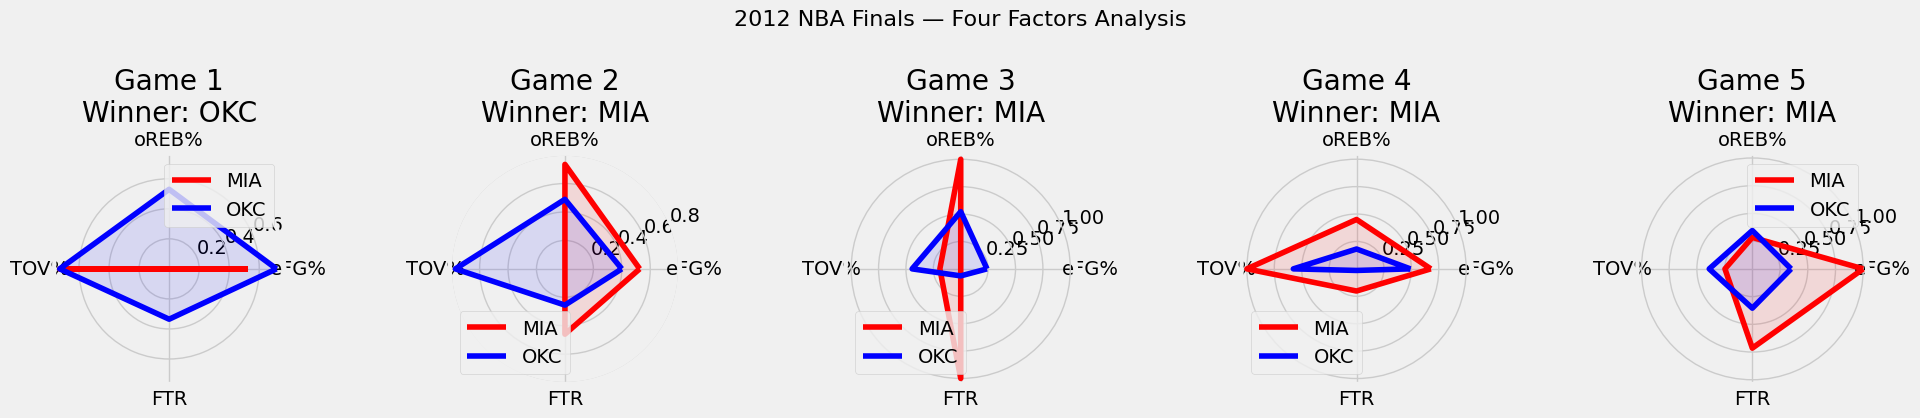

In [86]:
import numpy as np
import matplotlib.pyplot as plt

factors = ['eFG%_norm', 'oREB%_norm', 'TOV%_norm', 'ftR_norm']
factor_labels = ['eFG%', 'oREB%', 'TOV%', 'FTR']
num_factors = len(factors)

# Compute angle for each factor
angles = np.linspace(0, 2 * np.pi, num_factors, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

fig, axes = plt.subplots(1, 5, figsize=(20, 4), subplot_kw=dict(polar=True))
fig.suptitle('2012 NBA Finals — Four Factors Analysis', fontsize=16, y=1.02)

for i, game_num in enumerate([1, 2, 3, 4, 5]):
    ax = axes[i]
    game_data = four_factors_merged[four_factors_merged['GAME_NUMBER'] == game_num]
    # print(game_data)
    mia_team_data = game_data[game_data['teamTricode_x'] == 'MIA'][factors]
    mia_values = mia_team_data.values.flatten().tolist()
    mia_values += mia_values[:1]

    okc_team_data = game_data[game_data['teamTricode_x'] == 'OKC'][factors]
    okc_values = okc_team_data.values.flatten().tolist()
    okc_values += okc_values[:1]
    
    # print("Miami values,", mia_values)
    # print("OKC values,", okc_values)
    
    ax.plot(angles, mia_values, color='red', label='MIA')
    ax.fill(angles, mia_values, color='red', alpha=0.1)

    ax.plot(angles, okc_values, color='blue', label='OKC')
    ax.fill(angles, okc_values, color='blue', alpha=0.1)
    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(factor_labels)
    ax.set_title(f'Game {game_num}\nWinner: {"OKC" if game_num == 1 else "MIA"}')
    ax.legend()

plt.tight_layout()
plt.savefig('../data/four_factors_radar.png', dpi=150, bbox_inches='tight')